# K20 five-candidate comparison
The five candidates were selected using K20 development data. Bars are the average held-out accuracy of the saved stratified three folds; error bars are the sample standard deviation across those folds. K20 training was previously explored, and these results are not final test estimates.

The PDF currently uses standard Type-1 Times-Roman core font without embedding. Embed a properly licensed Times-compatible Type-1 font and inspect the final report PDF before submission.

findfont: Failed to find font weight normal for Times, now using roman.


findfont: Failed to find font weight normal for Times, now using roman.


findfont: Failed to find font weight normal for Times, now using roman.


findfont: Failed to find font weight normal for Times, now using roman.


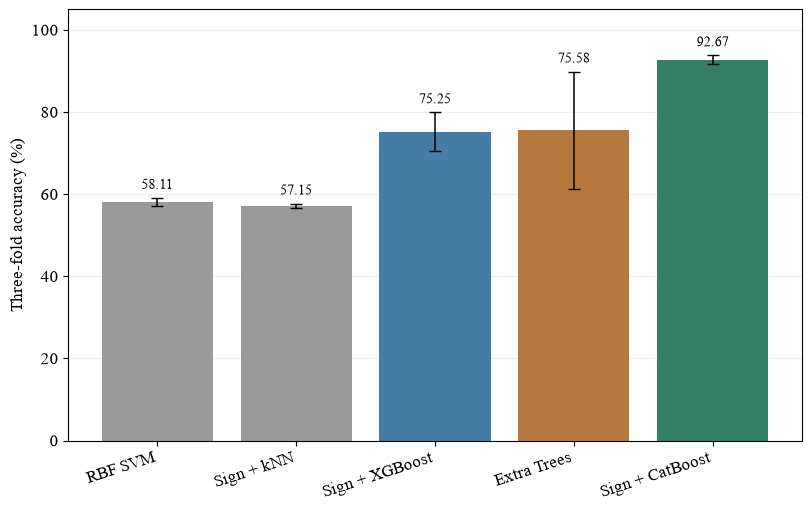

In [1]:
import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().resolve()
if root.name == 'B_Traditional_ML': root = root.parent
out = root / 'B_Traditional_ML' / 'results' / 'model_analysis'
with (out / 'comparison' / 'oof_metrics.csv').open(encoding='utf-8', newline='') as f: rows = {r['method']: r for r in csv.DictReader(f)}
methods = ['svm', 'knn', 'xgb', 'extra', 'catboost']
labels = ['RBF SVM', 'Sign + kNN', 'Sign + XGBoost', 'Extra Trees', 'Sign + CatBoost']
means = np.array([float(rows[k]['mean_fold_accuracy']) * 100 for k in methods])
sd = np.array([float(rows[k]['std_fold_accuracy']) * 100 for k in methods])
plt.rcParams.update({'pdf.use14corefonts': True, 'font.family': 'serif', 'font.serif': ['Times', 'Times New Roman'], 'font.size': 12})
fig, ax = plt.subplots(figsize=(8.0, 5.0), constrained_layout=True)
bars = ax.bar(np.arange(5), means, yerr=sd, capsize=4, color=['#9a9a9a','#9a9a9a','#467da5','#b7783e','#337f65'], error_kw={'elinewidth':1.1})
ax.set_xticks(np.arange(5), labels, rotation=18, ha='right')
ax.set_ylabel('Three-fold accuracy (%)')
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
for i, (mean, spread) in enumerate(zip(means, sd)): ax.text(i, mean + spread + 1.5, f'{mean:.2f}', ha='center', va='bottom', fontsize=10)
figure_dir = out / 'figures'
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / 'five_methods_k20.png', dpi=220)
fig.savefig(figure_dir / 'five_methods_k20.pdf')
plt.show()
